In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# print(os.getcwd())
# print(os.path.abspath(base_path))


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
# ls

In [3]:
base_path = "../results_mmlu_main"

folders = {

    3: "mmlu_test_eval_service_3_300",
    5: "mmlu_test_eval_service_5_300",
    8: "mmlu_test_eval_service_8_300",
    10: "mmlu_test_eval_service_10_300",
    12: "mmlu_test_eval_service_12_300",
    14: "mmlu_test_eval_service_14_300"

}

In [4]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)
#     print(folder_path)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)
#         print(file_path)

        with open(file_path, "r") as f:
            rows = json.load(f)
#             print(rows)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 12000 rows
K=5: loaded 16000 rows
K=8: loaded 22000 rows
K=10: loaded 26000 rows
K=12: loaded 30000 rows
K=14: loaded 34000 rows


In [5]:
df_k3 = pd.DataFrame(data[3])
df_k5 = pd.DataFrame(data[5])
df_k8 = pd.DataFrame(data[8])
df_k10 = pd.DataFrame(data[10])
df_k12 = pd.DataFrame(data[12])
df_k14 = pd.DataFrame(data[14])


print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)
print("K=12:", df_k12.shape)
print("K=14:", df_k14.shape)

K=3: (12000, 23)
K=5: (16000, 25)
K=8: (22000, 28)
K=10: (26000, 30)
K=12: (30000, 32)
K=14: (34000, 34)


In [6]:
# df_k3.columns.tolist()# df_k3.columns

### combined df

In [7]:
df_combined = pd.concat([df_k3, df_k5, df_k8, df_k10, df_k12, df_k14], ignore_index=True)

print(df_combined.shape)
print(df_combined["total_service_count"].value_counts())
# df_combined.columns

(140000, 34)
14    34000
12    30000
10    26000
8     22000
5     16000
3     12000
Name: total_service_count, dtype: int64


In [8]:
df_combined["K"] = df_combined["total_service_count"]

off_topic = df_combined[df_combined["expected_service"] == "general"]
off_topic = off_topic[off_topic["routing_method"] != "llm"]

print(off_topic.groupby(["model_name", "K"]).size().unstack()) 

K                                        3    5    8    10   12   14
model_name                                                          
BAAI/bge-large-en-v1.5                  300  300  300  300  300  300
BAAI/bge-reranker-v2-m3                 300  300  300  300  300  300
LiquidAI/LFM2-ColBERT-350M              300  300  300  300  300  300
Qwen/Qwen3-Embedding-0.6B               300  300  300  300  300  300
Qwen/Qwen3-Embedding-4B                 300  300  300  300  300  300
Qwen/Qwen3-Embedding-8B                 300  300  300  300  300  300
Qwen/Qwen3-Reranker-0.6B                300  300  300  300  300  300
Qwen/Qwen3-Reranker-4B                  300  300  300  300  300  300
Qwen/Qwen3-Reranker-8B                  300  300  300  300  300  300
colbert-ir/colbertv2.0                  300  300  300  300  300  300
lightonai/Reason-ModernColBERT          300  300  300  300  300  300
mixedbread-ai/mxbai-colbert-large-v1    300  300  300  300  300  300
mixedbread-ai/mxbai-rerank-large-v

# Preliminary Analysis 

## 1. Gap drifts

In [9]:
pool_columns = {
    3:  ["abstract_algebra_score", "anatomy_score", "astronomy_score"],
}
pool_columns[5]  = pool_columns[3]  + ["business_ethics_score", "college_computer_science_score"]
pool_columns[8]  = pool_columns[5]  + ["high_school_chemistry_score", "high_school_geography_score", "jurisprudence_score"]
pool_columns[10] = pool_columns[8]  + ["world_religions_score", "formal_logic_score"]
pool_columns[12] = pool_columns[10] + ["marketing_score", "sociology_score"]
pool_columns[14] = pool_columns[12] + ["high_school_psychology_score", "prehistory_score"]

In [10]:
results = []

for model_name in off_topic["model_name"].unique():
    for k_value in [3, 5, 8, 10, 12, 14]:

        rows = off_topic[(off_topic["model_name"] == model_name) & (off_topic["K"] == k_value)]

        score_table = rows[pool_columns[k_value]].to_numpy(dtype=float)  
#         print(score_table)
        
        highest_per_question = np.max(score_table, axis=1)
        median_per_question = np.median(score_table, axis=1)

        results.append({
            "model": model_name,
            "K": k_value,
            "number_of_questions": score_table.shape[0],
            "average_highest_score": np.mean(highest_per_question),
            "average_median_score": np.mean(median_per_question),
        })

summary = pd.DataFrame(results)
summary.head(12)

,model,K,number_of_questions,average_highest_score,average_median_score
0,Qwen/Qwen3-Embedding-0.6B,3,300,0.240252,0.179401
1,Qwen/Qwen3-Embedding-0.6B,5,300,0.246863,0.175729
2,Qwen/Qwen3-Embedding-0.6B,8,300,0.249435,0.157749
3,Qwen/Qwen3-Embedding-0.6B,10,300,0.250138,0.158376
4,Qwen/Qwen3-Embedding-0.6B,12,300,0.250153,0.144384
5,Qwen/Qwen3-Embedding-0.6B,14,300,0.250288,0.144635
6,mixedbread-ai/mxbai-rerank-large-v2,3,300,0.047053,0.021578
7,mixedbread-ai/mxbai-rerank-large-v2,5,300,0.058232,0.018094
8,mixedbread-ai/mxbai-rerank-large-v2,8,300,0.082676,0.018607
9,mixedbread-ai/mxbai-rerank-large-v2,10,300,0.088168,0.017940


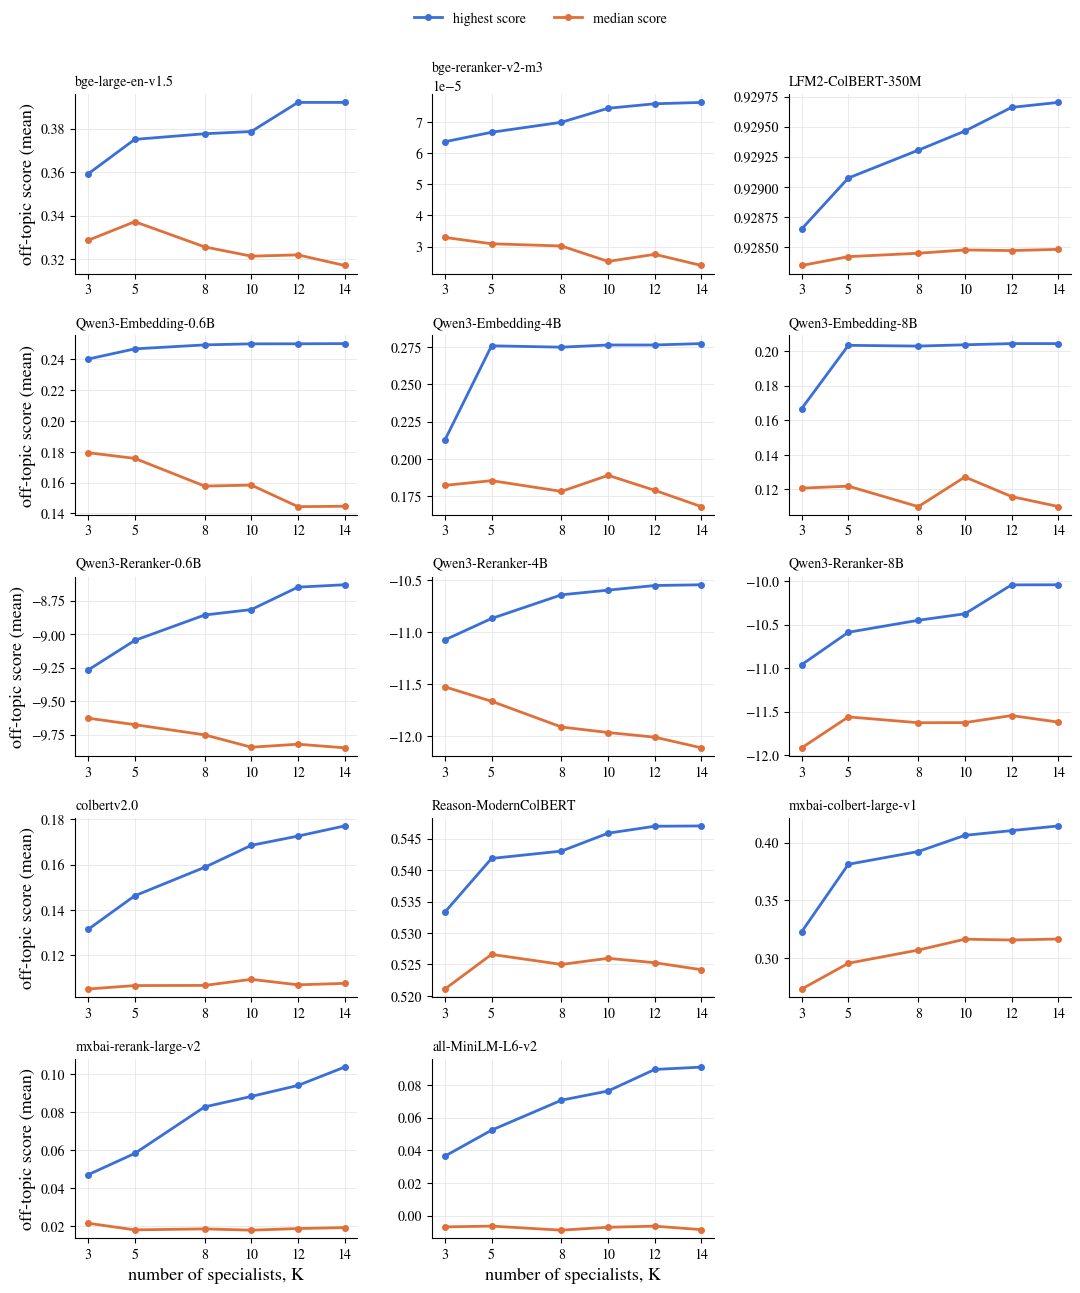

In [11]:
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 13, "axes.titlesize": 13, "axes.labelsize": 13,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

k_values = [3, 5, 8, 10, 12, 14]
model_names = sorted(summary["model"].unique())

blue = "#3A6FD8"
orange = "#E0703A"

# 14 models -> 5 rows x 3 columns
number_of_columns = 3
number_of_rows = int(np.ceil(len(model_names) / number_of_columns))
fig, axes = plt.subplots(number_of_rows, number_of_columns,
                         figsize=(11, 2.6 * number_of_rows), squeeze=False)
all_panels = axes.flatten()

for panel_number, model_name in enumerate(model_names):
    ax = all_panels[panel_number]

    model_summary = summary[summary["model"] == model_name].sort_values("K")

    ax.plot(model_summary["K"], model_summary["average_highest_score"],
            "-o", color=blue, linewidth=2, markersize=4, label="highest score")
    ax.plot(model_summary["K"], model_summary["average_median_score"],
            "-o", color=orange, linewidth=2, markersize=4, label="median score")

    short_name = model_name.split("/")[-1]       # "BAAI/bge-large-en-v1.5" -> "bge-large-en-v1.5"
    ax.set_title(short_name, loc="left", fontsize=10)
    ax.set_xticks(k_values)
    ax.grid(color="#e6e6e6", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

# hide the empty panel at the end (15 slots, 14 models)
for empty_panel in all_panels[len(model_names):]:
    empty_panel.axis("off")

# axis labels only on the outer panels
for ax in axes[:, 0]:
    ax.set_ylabel("off-topic score (mean)")
for ax in axes[-1, :]:
    ax.set_xlabel("number of specialists, K")

# one legend for the whole figure
handles, labels = all_panels[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False)

fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig("per_model_max_vs_median.pdf")
plt.show()

## 2. Gap distribution

In [12]:
# keep retrieval models only
retrieval = df_combined[df_combined["routing_method"] != "llm"].copy()
# print(retrieval.shape)

# label each row: specialist (in-scope) or general (off-topic)
retrieval["query_type"] = np.where(retrieval["expected_service"] == "general", "general", "specialist")

In [13]:
# gap = highest - median, using only the specialists in that row's pool
results = []

for k_value in [3, 5, 8, 10, 12, 14]:
    # 1. rows for this K
    rows_k = retrieval[retrieval["K"] == k_value].copy()

    # 2. only the scores of the specialists in this K's pool
    scores = rows_k[pool_columns[k_value]]

    # 3. per question: highest score, median score, gap
    rows_k["highest"] = scores.max(axis=1)
    rows_k["median"] = scores.median(axis=1)
    rows_k["my_gap"] = rows_k["highest"] - rows_k["median"]

    results.append(rows_k)

# 4. put all K back together
retrieval = pd.concat(results)


print("matches file gap:", np.allclose(retrieval["my_gap"], retrieval["gap"]))
retrieval[["model_name", "K", "query_type", "highest", "median", "my_gap"]].head()

matches file gap: True


,model_name,K,query_type,highest,median,my_gap
0,Qwen/Qwen3-Embedding-0.6B,3,specialist,0.474713,0.194414,0.280300
1,Qwen/Qwen3-Embedding-0.6B,3,specialist,0.473307,0.181658,0.291649
2,Qwen/Qwen3-Embedding-0.6B,3,specialist,0.405637,0.228629,0.177008
3,Qwen/Qwen3-Embedding-0.6B,3,specialist,0.349326,0.227777,0.121549
4,Qwen/Qwen3-Embedding-0.6B,3,specialist,0.297009,0.226982,0.070028


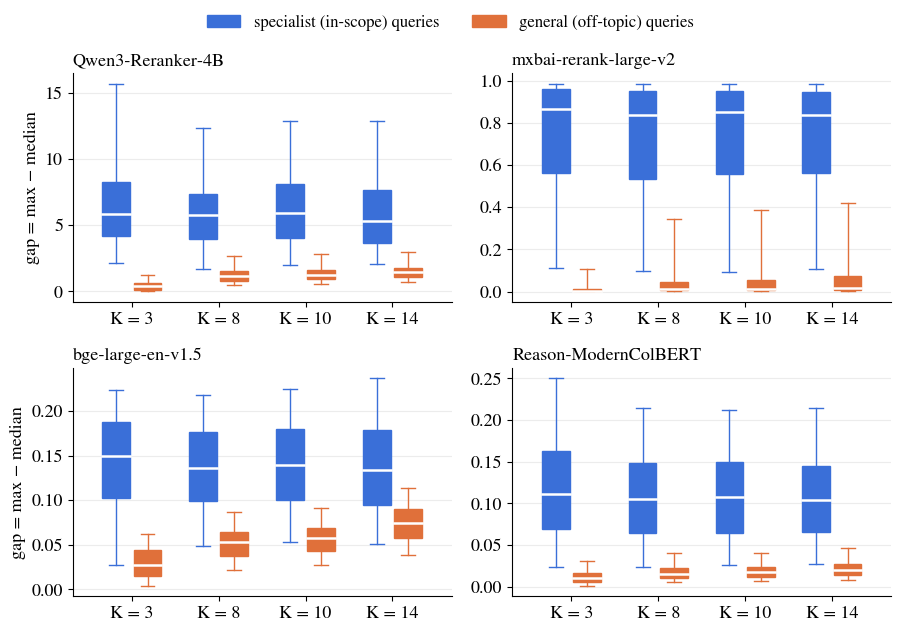

In [14]:
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 13, "axes.titlesize": 13, "axes.labelsize": 13,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12})

chosen_models = [
    ("Qwen/Qwen3-Reranker-4B",              "Qwen3-Reranker-4B"),
    ("mixedbread-ai/mxbai-rerank-large-v2", "mxbai-rerank-large-v2"),
    ("BAAI/bge-large-en-v1.5",              "bge-large-en-v1.5"),
    ("lightonai/Reason-ModernColBERT",      "Reason-ModernColBERT"),
]
k_to_show = [3, 8, 10, 14]
blue, orange = "#3A6FD8", "#E0703A"

fig, axes = plt.subplots(2, 2, figsize=(9.2, 6.4))

for ax, (model_name, short_name) in zip(axes.flatten(), chosen_models):
    model_rows = retrieval[retrieval["model_name"] == model_name]

    specialist_gaps = []
    general_gaps = []
    for k_value in k_to_show:
        rows_k = model_rows[model_rows["K"] == k_value]
        specialist_gaps.append(rows_k[rows_k["query_type"] == "specialist"]["my_gap"])
        general_gaps.append(rows_k[rows_k["query_type"] == "general"]["my_gap"])

    positions = np.arange(len(k_to_show))
    for gaps, shift, colour in [(specialist_gaps, -0.18, blue), (general_gaps, 0.18, orange)]:
        ax.boxplot(gaps, positions=positions + shift, widths=0.32,
                   whis=(5, 95), showfliers=False, patch_artist=True,
                   medianprops=dict(color="white", linewidth=1.8),
                   boxprops=dict(facecolor=colour, edgecolor=colour),
                   whiskerprops=dict(color=colour), capprops=dict(color=colour))

    ax.set_xticks(positions)
    ax.set_xticklabels([f"K = {k}" for k in k_to_show])
    ax.set_title(short_name, loc="left", fontsize=13)
    ax.grid(axis="y", color="#ececec")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("gap = max − median")

from matplotlib.patches import Patch
fig.legend([Patch(color=blue), Patch(color=orange)],
           ["specialist (in-scope) queries", "general (off-topic) queries"],
           loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("gap_boxplots.pdf")
plt.show()

## Ablation k-aware threshold

In [15]:
models = ["BAAI/bge-large-en-v1.5",
          "lightonai/Reason-ModernColBERT",
          "Qwen/Qwen3-Reranker-4B"]

df_k = df_combined[df_combined["model_name"].isin(models)]

keys = ["model_name", "routing_method", "total_service_count"]

acc  = df_k.groupby(keys)["is_correct"].mean() * 100
spec = df_k[df_k["expected_service"] != "general"].groupby(keys)["is_correct"].mean() * 100
gen  = df_k[df_k["expected_service"] == "general"].groupby(keys)["is_correct"].mean() * 100

table = pd.DataFrame({"k-aware Acc": acc,
                      "k-aware Spec": spec,
                      "k-aware Gen": gen}).round(2)
table
# print(table.to_latex(float_format="%.2f"))

k-aware Acc  \
model_name                     routing_method total_service_count                
BAAI/bge-large-en-v1.5         bi-encoder     3                          91.67   
                                              5                          89.00   
                                              8                          82.82   
                                              10                         80.77   
                                              12                         71.27   
                                              14                         69.00   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                          97.50   
                                              5                          95.12   
                                              8                          87.64   
                                              10                         87.15   
                                              12                         82.73   
                                              14                         81.35   
lightonai/Reason-ModernColBERT colbert        3                          91.67   
                                              5                          89.88   
                                              8                          83.55   
                                              10                         80.46   
                                              12                         74.87   
                                              14                         72.35   

                                                                   k-aware Spec  \
model_name                     routing_method total_service_count                 
BAAI/bge-large-en-v1.5         bi-encoder     3                           89.33   
                                              5                           86.80   
                                              8                           80.38   
                                              10                          78.20   
                                              12                          70.75   
                                              14                          68.36   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                           98.33   
                                              5                           96.40   
                                              8                           89.88   
                                              10                          88.40   
                                              12                          83.17   
                                              14                          81.50   
lightonai/Reason-ModernColBERT colbert        3                           94.33   
                                              5                           88.40   
                                              8                           79.75   
                                              10                          76.30   
                                              12                          70.17   
                                              14                          67.79   

                                                                   k-aware Gen  
model_name                     routing_method total_service_count               
BAAI/bge-large-en-v1.5         bi-encoder     3                          94.00  
                                              5                          92.67  
                                              8                          89.33  
                                              10                         89.33  
                                              12                         73.33  
                                              14                         72.00  
Qwen/Qwen3-Reranker-4B         cross-encoder  3                          96.67  
                                    

In [16]:
gap = df_k[df_k["expected_service"] == "general"].groupby(keys)["gap"].mean()

table = pd.DataFrame({
                      "Off-topic gap": gap}).round(3)
table

Off-topic gap
model_name                     routing_method total_service_count               
BAAI/bge-large-en-v1.5         bi-encoder     3                            0.031
                                              5                            0.038
                                              8                            0.052
                                              10                           0.057
                                              12                           0.070
                                              14                           0.075
Qwen/Qwen3-Reranker-4B         cross-encoder  3                            0.452
                                              5                            0.797
                                              8                            1.273
                                              10                           1.371
                                              12                           1.460
                                              14                           1.569
lightonai/Reason-ModernColBERT colbert        3                            0.012
                                              5                            0.015
                                              8                            0.018
                                              10                           0.020
                                              12                           0.022
                                              14                           0.023

In [17]:
# # Specialist queries only: what happened to each one
# s = df_k[df_k["expected_service"] != "general"].copy()
# s["outcome"] = "confused"                                          # wrong specialist
# s.loc[s["is_correct"], "outcome"] = "correct"                      # right specialist
# s.loc[s["predicted_label"] == "general", "outcome"] = "rejected"   # sent to general

# share = (s.groupby(keys)["outcome"].value_counts(normalize=True)
#           .unstack().mul(100).fillna(0))

# table = pd.DataFrame({"Acc.": acc.round(2), "Spec.": spec.round(2), "Gen.": gen.round(2),
#                       "Rejected": share["rejected"].round(1),
#                       "Confused": share["confused"].round(1),
#                       "Off-topic gap": gap.round(3)})
# table

## Can Retrieval models route?

In [18]:
df_acc = df_combined.copy()     

acc_table = df_acc.pivot_table(
    index=["routing_method", "model_name"],
    columns="total_service_count",
    values="is_correct",
    aggfunc="mean",
).mul(100).round(2)

acc_table = acc_table.sort_values(["routing_method", 14], ascending=[True, False])
# acc_table.to_latex()
acc_table

total_service_count                                       3      5      8   \
routing_method model_name                                                    
bi-encoder     BAAI/bge-large-en-v1.5                  91.67  89.00  82.82   
               sentence-transformers/all-MiniLM-L6-v2  88.83  80.50  74.73   
               Qwen/Qwen3-Embedding-8B                 88.67  83.00  74.55   
               Qwen/Qwen3-Embedding-0.6B               83.00  78.75  71.27   
               Qwen/Qwen3-Embedding-4B                 89.67  75.12  65.64   
colbert        lightonai/Reason-ModernColBERT          91.67  89.88  83.55   
               LiquidAI/LFM2-ColBERT-350M              93.33  85.12  81.45   
               mixedbread-ai/mxbai-colbert-large-v1    80.50  71.12  67.91   
               colbert-ir/colbertv2.0                  77.00  66.12  58.36   
cross-encoder  Qwen/Qwen3-Reranker-8B                  87.50  93.00  90.09   
               Qwen/Qwen3-Reranker-4B                  97.50  95.12  87.64   
               mixedbread-ai/mxbai-rerank-large-v2     94.67  90.00  84.09   
               Qwen/Qwen3-Reranker-0.6B                94.17  87.50  82.36   
               BAAI/bge-reranker-v2-m3                 92.83  84.50  72.00   
llm            qwen3:32b                               96.33  94.12  92.64   
               qwen2.5:32b                             88.67  86.62  84.36   
               phi4:14b                                71.17  79.12  86.64   
               qwen2.5:14b                             96.67  92.88  84.27   
               llama3.1:8b                             77.67  69.88  73.91   
               qwen2.5:7b                              74.33  64.12  62.91   

total_service_count                                       10     12     14  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  80.77  71.27  69.00  
               sentence-transformers/all-MiniLM-L6-v2  73.62  69.53  66.82  
               Qwen/Qwen3-Embedding-8B                 71.69  66.13  63.06  
               Qwen/Qwen3-Embedding-0.6B               69.77  64.67  62.18  
               Qwen/Qwen3-Embedding-4B                 64.46  57.53  54.76  
colbert        lightonai/Reason-ModernColBERT          80.46  74.87  72.35  
               LiquidAI/LFM2-ColBERT-350M              77.38  71.60  69.59  
               mixedbread-ai/mxbai-colbert-large-v1    64.00  60.33  56.94  
               colbert-ir/colbertv2.0                  57.46  54.67  50.47  
cross-encoder  Qwen/Qwen3-Reranker-8B                  89.85  84.80  82.47  
               Qwen/Qwen3-Reranker-4B                  87.15  82.73  81.35  
               mixedbread-ai/mxbai-rerank-large-v2     82.54  76.73  74.71  
               Qwen/Qwen3-Reranker-0.6B                78.62  73.53  70.35  
               BAAI/bge-reranker-v2-m3                 70.23  65.00  59.71  
llm            qwen3:32b                               92.31  87.60  86.88  
               qwen2.5:32b                             85.77  81.53  79.76  
               phi4:14b                                86.08  81.60  79.47  
               qwen2.5:14b                             85.62  78.47  77.47  
               llama3.1:8b                             70.31  68.07  66.18  
               qwen2.5:7b                              57.62  58.13  54.88

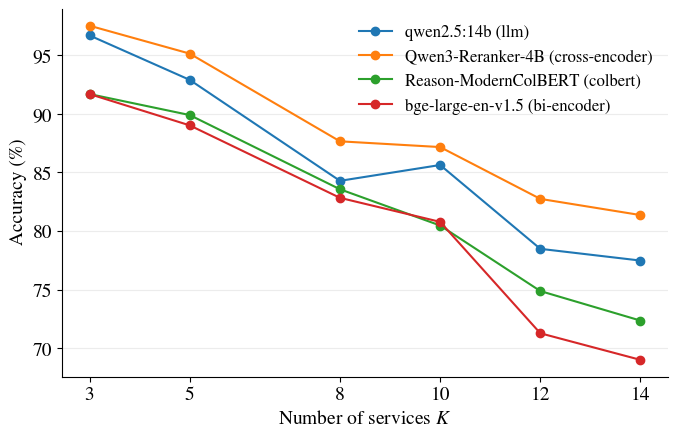

In [19]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 14, "axes.titlesize": 14, "axes.labelsize": 14,
                     "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 12})



acc = acc_table.copy()
Ks = list(acc.columns)                                   

chosen = [
    ("llm",           "qwen2.5:14b"),
    ("cross-encoder", "Qwen/Qwen3-Reranker-4B"),
    ("colbert",       "lightonai/Reason-ModernColBERT"),
    ("bi-encoder",    "BAAI/bge-large-en-v1.5"),
]

fig, ax = plt.subplots(figsize=(7, 4.6))
for family, model in chosen:
    row = acc.loc[(family, model), Ks]
    ax.plot(Ks, row, marker="o", label=f"{model.split('/')[-1]} ({family})")

ax.set_xticks(Ks)
ax.set_xlabel("Number of services $K$")
ax.set_ylabel(" Accuracy (%)")
ax.grid(axis="y", color="#ececec")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig("accuracy_decay.pdf")
plt.show()

## How well are specialist and off-topic queries routed?

In [20]:
keys = ["routing_method", "model_name", "total_service_count"]
is_general = df_acc["expected_service"] == "general"

acc  = df_acc.groupby(keys)["is_correct"].mean() * 100
spec = df_acc[~is_general].groupby(keys)["is_correct"].mean() * 100
gen  = df_acc[is_general].groupby(keys)["is_correct"].mean() * 100

df_recall = pd.DataFrame({"Acc.": acc, "Spec.": spec, "Gen.": gen}).round(2)
df_recall

k3_recall  = df_recall.xs(3,  level="total_service_count")
k14_recall = df_recall.xs(14, level="total_service_count")

recall_k3_k14 = pd.concat([k3_recall, k14_recall], axis=1, keys=["K=3", "K=14"])
recall_k3_k14

K=3                 \
                                                        Acc.  Spec.    Gen.   
routing_method model_name                                                     
bi-encoder     BAAI/bge-large-en-v1.5                  91.67  89.33   94.00   
               Qwen/Qwen3-Embedding-0.6B               83.00  80.00   86.00   
               Qwen/Qwen3-Embedding-4B                 89.67  80.33   99.00   
               Qwen/Qwen3-Embedding-8B                 88.67  83.67   93.67   
               sentence-transformers/all-MiniLM-L6-v2  88.83  86.67   91.00   
colbert        LiquidAI/LFM2-ColBERT-350M              93.33  92.67   94.00   
               colbert-ir/colbertv2.0                  77.00  60.67   93.33   
               lightonai/Reason-ModernColBERT          91.67  94.33   89.00   
               mixedbread-ai/mxbai-colbert-large-v1    80.50  74.00   87.00   
cross-encoder  BAAI/bge-reranker-v2-m3                 92.83  90.67   95.00   
               Qwen/Qwen3-Reranker-0.6B                94.17  92.00   96.33   
               Qwen/Qwen3-Reranker-4B                  97.50  98.33   96.67   
               Qwen/Qwen3-Reranker-8B                  87.50  97.33   77.67   
               mixedbread-ai/mxbai-rerank-large-v2     94.67  93.67   95.67   
llm            llama3.1:8b                             77.67  96.00   59.33   
               phi4:14b                                71.17  45.33   97.00   
               qwen2.5:14b                             96.67  94.00   99.33   
               qwen2.5:32b                             88.67  77.33  100.00   
               qwen2.5:7b                              74.33  48.67  100.00   
               qwen3:32b                               96.33  93.67   99.00   

                                                        K=14                
                                                        Acc.  Spec.   Gen.  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  69.00  68.36  72.00  
               Qwen/Qwen3-Embedding-0.6B               62.18  55.64  92.67  
               Qwen/Qwen3-Embedding-4B                 54.76  45.79  96.67  
               Qwen/Qwen3-Embedding-8B                 63.06  55.50  98.33  
               sentence-transformers/all-MiniLM-L6-v2  66.82  62.36  87.67  
colbert        LiquidAI/LFM2-ColBERT-350M              69.59  66.64  83.33  
               colbert-ir/colbertv2.0                  50.47  42.86  86.00  
               lightonai/Reason-ModernColBERT          72.35  67.79  93.67  
               mixedbread-ai/mxbai-colbert-large-v1    56.94  51.21  83.67  
cross-encoder  BAAI/bge-reranker-v2-m3                 59.71  52.36  94.00  
               Qwen/Qwen3-Reranker-0.6B                70.35  67.57  83.33  
               Qwen/Qwen3-Reranker-4B                  81.35  81.50  80.67  
               Qwen/Qwen3-Reranker-8B                  82.47  81.36  87.67  
               mixedbread-ai/mxbai-rerank-large-v2     74.71  70.36  95.00  
llm            llama3.1:8b                             66.18  74.79  26.00  
               phi4:14b                                79.47  75.29  99.00  
               qwen2.5:14b                             77.47  81.14  60.33  
               qwen2.5:32b                             79.76  76.00  97.33  
               qwen2.5:7b                              54.88  45.36  99.33  
               qwen3:32b                               86.88  85.71  92.33

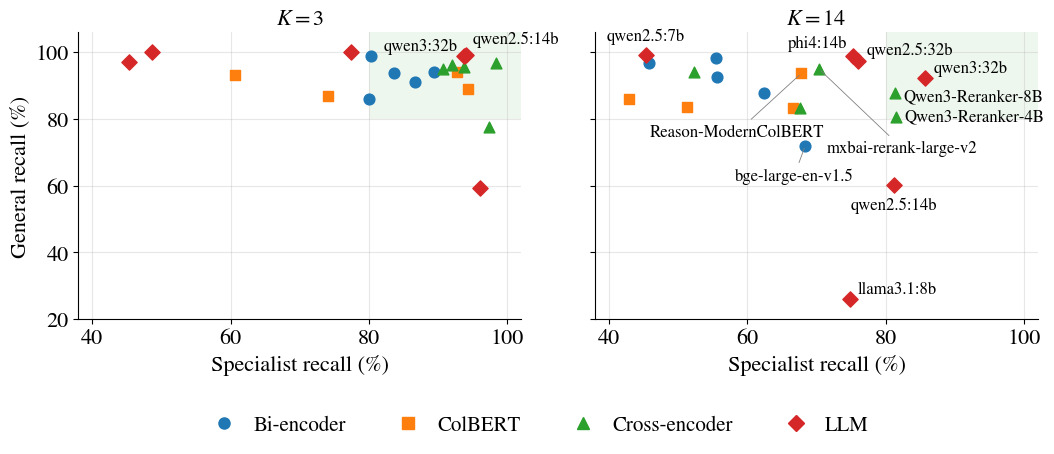

In [21]:
# from matplotlib.patches import Rectangle

# plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
#                      "font.size": 13, "axes.titlesize": 13, "axes.labelsize": 13,
#                      "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

# style = {"bi-encoder": ("o", "tab:blue", "Bi-encoder"),
#          "colbert": ("s", "tab:orange", "ColBERT"),
#          "cross-encoder": ("^", "tab:green", "Cross-encoder"),
#          "llm": ("D", "tab:red", "LLM")}

# labels = {
#     3:  {"qwen3:32b": (-8, -3),
#          "qwen2.5:14b": (0, 8),},
#    14: {"qwen3:32b": (6, 4),
#          "Qwen3-Reranker-8B": (6, -12),
#          "Qwen3-Reranker-4B": (6, -3),
#          "qwen2.5:32b": (6, 5),
#          "phi4:14b": (0, 6),
#          "Reason-ModernColBERT": (-46, -53),        
#          "mxbai-rerank-large-v2": (45, -80),        
#          "bge-large-en-v1.5": (-8, -3),
#          "qwen2.5:14b": (0, -14),
#          "qwen2.5:7b": (0, 8),                      
#          "llama3.1:8b": (6, 4)}, 
# }

# both = recall_k3_k14

# fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
# for ax, k in zip(axes, [3, 14]):
#     spec, gen = both[(f"K={k}", "Spec.")], both[(f"K={k}", "Gen.")]

#     ax.add_patch(Rectangle((80, 80), 30, 30, color="tab:green", alpha=0.08, lw=0, zorder=0))

#     for fam, (marker, color, name) in style.items():
#         ax.scatter(spec.loc[fam], gen.loc[fam], marker=marker, color=color,
#                    s=50, label=name, zorder=3)

#     for fam, router in both.index:
#         short = router.split("/")[-1]
#         if short in labels[k]:
#             dx, dy = labels[k][short]
#             far = abs(dx) > 20 or abs(dy) > 20     # far label: centred, with a thin line
#             ha = "center" if far or dx == 0 else "right" if dx < 0 else "left"
#             ax.annotate(short, (spec[(fam, router)], gen[(fam, router)]),
#                         xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=8,
#                         arrowprops=dict(arrowstyle="-", lw=0.6, color="gray") if far else None)

#     ax.set_title(f"$K={k}$")
#     ax.set_xlabel("Specialist recall (%)")
#     ax.set_xlim(38, 102)
#     ax.set_ylim(20, 106)
#     ax.grid(alpha=0.3)

# axes[0].set_ylabel("General recall (%)")
# axes[0].legend(loc="lower left", fontsize=8)
# plt.tight_layout()
# plt.savefig("recall_scatter.pdf")
# plt.show()

from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 16, "axes.titlesize": 16, "axes.labelsize": 16,
                     "xtick.labelsize": 16, "ytick.labelsize": 16, "legend.fontsize": 15})

style = {"bi-encoder":    ("o", "tab:blue",   "Bi-encoder"),
         "colbert":       ("s", "tab:orange", "ColBERT"),
         "cross-encoder": ("^", "tab:green",  "Cross-encoder"),
         "llm":           ("D", "tab:red",    "LLM")}

labels = {
    3:  {"qwen3:32b": (-4, 4),
         "qwen2.5:14b": (5, 8),},
   14: {"qwen3:32b": (6, 4),
         "Qwen3-Reranker-8B": (6, -5),
         "Qwen3-Reranker-4B": (6, -3),
         "qwen2.5:32b": (6, 5),
         "phi4:14b": (-4, 6),
         "Reason-ModernColBERT": (-46, -45),
         "mxbai-rerank-large-v2": (60, -60),
         "bge-large-en-v1.5": (-8, -25),
         "qwen2.5:14b": (0, -18),
         "qwen2.5:7b": (0, 10),
         "llama3.1:8b": (6, 4)},
}

both = recall_k3_k14

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, k in zip(axes, [3, 14]):
    spec, gen = both[(f"K={k}", "Spec.")], both[(f"K={k}", "Gen.")]

    ax.add_patch(Rectangle((80, 80), 30, 30, color="tab:green", alpha=0.08, lw=0, zorder=0))

    for fam, (marker, color, name) in style.items():
        ax.scatter(spec.loc[fam], gen.loc[fam], marker=marker, color=color, s=60, zorder=3)

    for fam, router in both.index:
        short = router.split("/")[-1]
        if short in labels[k]:
            dx, dy = labels[k][short]
            far = abs(dx) > 20 or abs(dy) > 20     
            ha = "center" if far or dx == 0 else "right" if dx < 0 else "left"
            ax.annotate(short, (spec[(fam, router)], gen[(fam, router)]),
                        xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=12,
                        arrowprops=dict(arrowstyle="-", lw=0.6, color="gray") if far else None)

    ax.set_title(f"$K={k}$")
    ax.set_xlabel("Specialist recall (%)")
    ax.set_xlim(38, 102)
    ax.set_ylim(20, 106)
    ax.grid(alpha=0.3)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("General recall (%)")

handles = [Line2D([], [], marker=m, ls="", color=c, ms=8, label=n) for m, c, n in style.values()]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.02), columnspacing=2.0, handletextpad=0.4)

plt.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig("recall_scatter.pdf", bbox_inches="tight")
plt.show()

## What does routing cost?

In [23]:
df_cost = df_combined.copy() 

In [33]:
# lat against all k 

# convert energy to mWh
df_cost["energy_mwh"] = df_cost["energy_kwh"] * 1_000_000

lat_all_k = (df_cost
       .groupby(["routing_method", "model_name", "total_service_count"])["latency_ms"]
       .median()
       .unstack("total_service_count"))
lat_all_k


total_service_count                                             3   \
routing_method model_name                                            
bi-encoder     BAAI/bge-large-en-v1.5                    14.259158   
               Qwen/Qwen3-Embedding-0.6B                 29.218834   
               Qwen/Qwen3-Embedding-4B                   38.642646   
               Qwen/Qwen3-Embedding-8B                   36.850527   
               sentence-transformers/all-MiniLM-L6-v2     4.807793   
colbert        LiquidAI/LFM2-ColBERT-350M                14.567956   
               colbert-ir/colbertv2.0                     9.385190   
               lightonai/Reason-ModernColBERT            15.824815   
               mixedbread-ai/mxbai-colbert-large-v1      16.049722   
cross-encoder  BAAI/bge-reranker-v2-m3                   25.143710   
               Qwen/Qwen3-Reranker-0.6B                  32.815672   
               Qwen/Qwen3-Reranker-4B                    44.744222   
               Qwen/Qwen3-Reranker-8B                    59.796803   
               mixedbread-ai/mxbai-rerank-large-v2       28.059963   
llm            llama3.1:8b                               42.584796   
               phi4:14b                                  67.228752   
               qwen2.5:14b                               72.142917   
               qwen2.5:32b                              132.134290   
               qwen2.5:7b                                44.808680   
               qwen3:32b                               5197.933255   

total_service_count                                             5   \
routing_method model_name                                            
bi-encoder     BAAI/bge-large-en-v1.5                    14.280054   
               Qwen/Qwen3-Embedding-0.6B                 29.213135   
               Qwen/Qwen3-Embedding-4B                   37.626880   
               Qwen/Qwen3-Embedding-8B                   37.514121   
               sentence-transformers/all-MiniLM-L6-v2     4.886983   
colbert        LiquidAI/LFM2-ColBERT-350M                14.635623   
               colbert-ir/colbertv2.0                     9.416290   
               lightonai/Reason-ModernColBERT            16.190346   
               mixedbread-ai/mxbai-colbert-large-v1      16.122916   
cross-encoder  BAAI/bge-reranker-v2-m3                   34.583134   
               Qwen/Qwen3-Reranker-0.6B                  33.452421   
               Qwen/Qwen3-Reranker-4B                    62.303739   
               Qwen/Qwen3-Reranker-8B                    99.424993   
               mixedbread-ai/mxbai-rerank-large-v2       28.929529   
llm            llama3.1:8b                               47.474232   
               phi4:14b                                  69.229873   
               qwen2.5:14b                               75.962120   
               qwen2.5:32b                              135.982489   
               qwen2.5:7b                                46.539822   
               qwen3:32b                               5645.097666   

total_service_count                                             8   \
routing_method model_name                                            
bi-encoder     BAAI/bge-large-en-v1.5                    14.278527   
               Qwen/Qwen3-Embedding-0.6B                 29.231733   
               Qwen/Qwen3-Embedding-4B                   37.470572   
               Qwen/Qwen3-Embedding-8B                   37.268230   
               sentence-transformers/all-MiniLM-L6-v2     4.936390   
colbert        LiquidAI/LFM2-ColBERT-350M                14.593827   
               colbert-ir/colbertv2.0                     9.579240   
               lightonai/Reason-ModernColBERT            16.110700   
               mixedbread-ai/mxbai-colbert-large-v1      16.391680   
cross-encoder  BAAI/bge-reranker-v2-m3                   49.677804   
               Qwen/Qwen3-Reranker-0.6B                  34.197151   
        

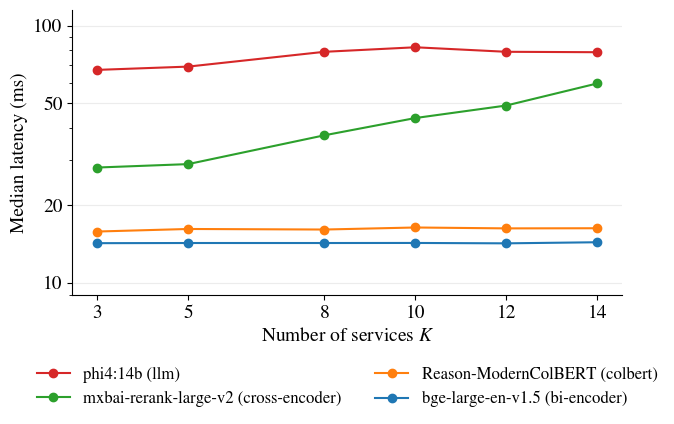

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 14, "axes.titlesize": 14, "axes.labelsize": 14,
                     "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 12})

Ks = list(lat_all_k.columns)

family_color = {"llm": "tab:red", "cross-encoder": "tab:green",
                "colbert": "tab:orange", "bi-encoder": "tab:blue"}

chosen = [
    ("llm",           "phi4:14b"),
    ("cross-encoder", "mixedbread-ai/mxbai-rerank-large-v2"),
    ("colbert",       "lightonai/Reason-ModernColBERT"),
    ("bi-encoder",    "BAAI/bge-large-en-v1.5"),
]

fig, ax = plt.subplots(figsize=(7, 4.6))
for family, model in chosen:
    row = lat_all_k.loc[(family, model), Ks]
    ax.plot(Ks, row, marker="o", color=family_color[family],
            label=f"{model.split('/')[-1]} ({family})")

ax.set_xticks(Ks)
ax.set_yscale("log")
ax.set_ylim(9, 115)                                                  # fixed range
ax.set_yticks([10, 20, 50, 100]); ax.set_yticklabels(["10", "20", "50", "100"])
ax.yaxis.set_minor_formatter(NullFormatter())                        # no 6x10^1, 4x10^1 ... labels
ax.set_xlabel("Number of services $K$")
ax.set_ylabel("Median latency (ms)")
ax.grid(axis="y", color="#ececec")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

fig.tight_layout()
fig.savefig("latency_vs_k.pdf", bbox_inches="tight")
plt.show()

In [145]:
# convert energy to mWh

df_cost["energy_mwh"] = df_cost["energy_kwh"] * 1_000_000


lat = (df_cost[df_cost["total_service_count"].isin([14])]
       .groupby(["routing_method", "model_name", "total_service_count"])["latency_ms"]
       .median()
       .unstack("total_service_count"))
lat

total_service_count                                             14
routing_method model_name                                         
bi-encoder     BAAI/bge-large-en-v1.5                    14.377516
               Qwen/Qwen3-Embedding-0.6B                 29.329899
               Qwen/Qwen3-Embedding-4B                   37.577083
               Qwen/Qwen3-Embedding-8B                   37.433325
               sentence-transformers/all-MiniLM-L6-v2     4.935172
colbert        LiquidAI/LFM2-ColBERT-350M                14.769075
               colbert-ir/colbertv2.0                     9.559965
               lightonai/Reason-ModernColBERT            16.296974
               mixedbread-ai/mxbai-colbert-large-v1      16.345339
cross-encoder  BAAI/bge-reranker-v2-m3                   75.324194
               Qwen/Qwen3-Reranker-0.6B                  40.959907
               Qwen/Qwen3-Reranker-4B                   142.352894
               Qwen/Qwen3-Reranker-8B                   219.215223
               mixedbread-ai/mxbai-rerank-large-v2       59.532795
llm            llama3.1:8b                               54.324337
               phi4:14b                                  78.751384
               qwen2.5:14b                               93.835631
               qwen2.5:32b                              150.947071
               qwen2.5:7b                                51.520173
               qwen3:32b                               6512.118548

In [35]:
keys = ["routing_method", "model_name", "total_service_count"]

energy_stats = (df_cost.groupby(keys)["energy_mwh"]
                .agg(["median", "mean"])
                .unstack("total_service_count")
                .round(3))
energy_stats

median           \
total_service_count                                         3        5    
routing_method model_name                                                 
bi-encoder     BAAI/bge-large-en-v1.5                    0.062    1.589   
               Qwen/Qwen3-Embedding-0.6B                 1.718    1.659   
               Qwen/Qwen3-Embedding-4B                   3.000    1.691   
               Qwen/Qwen3-Embedding-8B                   1.702    1.681   
               sentence-transformers/all-MiniLM-L6-v2    0.033    0.032   
colbert        LiquidAI/LFM2-ColBERT-350M                0.068    1.590   
               colbert-ir/colbertv2.0                    0.046    0.046   
               lightonai/Reason-ModernColBERT            0.065    1.598   
               mixedbread-ai/mxbai-colbert-large-v1      0.068    0.823   
cross-encoder  BAAI/bge-reranker-v2-m3                   1.623    1.698   
               Qwen/Qwen3-Reranker-0.6B                  1.671    1.673   
               Qwen/Qwen3-Reranker-4B                    6.019    8.019   
               Qwen/Qwen3-Reranker-8B                    7.916    9.053   
               mixedbread-ai/mxbai-rerank-large-v2       1.643    1.643   
llm            llama3.1:8b                               4.979    5.921   
               phi4:14b                                  8.263    8.349   
               qwen2.5:14b                               7.715    8.030   
               qwen2.5:32b                              10.518   16.805   
               qwen2.5:7b                                5.008    5.167   
               qwen3:32b                               520.477  569.625   

                                                                         \
total_service_count                                         8        10   
routing_method model_name                                                 
bi-encoder     BAAI/bge-large-en-v1.5                    0.063    1.593   
               Qwen/Qwen3-Embedding-0.6B                 1.649    1.649   
               Qwen/Qwen3-Embedding-4B                   1.697    1.691   
               Qwen/Qwen3-Embedding-8B                   1.682    1.676   
               sentence-transformers/all-MiniLM-L6-v2    0.032    0.032   
colbert        LiquidAI/LFM2-ColBERT-350M                1.600    1.591   
               colbert-ir/colbertv2.0                    0.045    0.048   
               lightonai/Reason-ModernColBERT            1.590    1.585   
               mixedbread-ai/mxbai-colbert-large-v1      0.065    1.597   
cross-encoder  BAAI/bge-reranker-v2-m3                   7.080    8.257   
               Qwen/Qwen3-Reranker-0.6B                  1.680    1.696   
               Qwen/Qwen3-Reranker-4B                    8.943    9.416   
               Qwen/Qwen3-Reranker-8B                   16.568   19.009   
               mixedbread-ai/mxbai-rerank-large-v2       5.222    6.377   
llm            llama3.1:8b                               5.769    6.268   
               phi4:14b                                  8.349    8.396   
               qwen2.5:14b                               8.130    8.166   
               qwen2.5:32b                              17.917   18.111   
               qwen2.5:7b                                5.295    6.693   
               qwen3:32b                               634.571  630.814   

                                                                         \
total_service_count                                         12       14   
routing_method model_name                                                 
bi-encoder     BAAI/bge-large-en-v1.5                    1.596    0.060   
               Qwen/Qwen3-Embedding-0.6B                 1.660    1.660   
               Qwen/Qwen3-Embedding-4B                   1.710    1.694   
               Qwen/Qwen3-Embedding-8B                   1.691    1.709   
               sentence-transformers/all-MiniLM-L6-v2    0.031    0.032   
colb

In [144]:
# lat_plot = lat.copy()          # your DataFrame: index (routing_method, model_name), columns K
# Ks = list(lat_plot.columns)

# style = {"bi-encoder":    ("o", "#1f77b4"),
#          "colbert":       ("s", "#ff7f0e"),
#          "cross-encoder": ("^", "#2ca02c"),
#          "llm":           ("D", "#d62728")}

# chosen = [
#     ("llm",           "qwen2.5:14b"),
#     ("cross-encoder", "Qwen/Qwen3-Reranker-4B"),
#     ("colbert",       "lightonai/Reason-ModernColBERT"),
#     ("bi-encoder",    "BAAI/bge-large-en-v1.5"),
# ]

# fig, ax = plt.subplots(figsize=(7, 4.6))
# for family, model in chosen:
#     marker, color = style[family]
#     ax.plot(Ks, lat_plot.loc[(family, model), Ks], marker=marker, color=color,
#             label=f"{model.split('/')[-1]} ({family})")

# ax.set_yscale("log")
# ax.set_xticks(Ks)
# ax.set_xlabel("Number of services $K$")
# ax.set_ylabel("Median latency (ms)")
# ax.grid(axis="y", color="#ececec")
# ax.set_axisbelow(True)
# ax.spines[["top", "right"]].set_visible(False)
# ax.legend(frameon=False)
# fig.tight_layout()
# fig.savefig("latency_vs_k.pdf")

In [147]:
k14_cost = df_cost[df_cost["total_service_count"] == 14]
group_k14_cost = k14_cost.groupby(["routing_method", "model_name"])

acc_cost = group_k14_cost["is_correct"].mean() * 100
energy_cost = group_k14_cost["energy_mwh"].mean()

In [148]:
table_cost = pd.DataFrame({
    "Acc. K=14 (%)": acc_cost,
#     "Lat. K=3 (ms)": lat[3],
    "Lat. K=14 (ms)": lat[14],
    "Energy K=14 (mWh)": energy_cost,
}).round(2)

table_cost

Acc. K=14 (%)  \
routing_method model_name                                              
bi-encoder     BAAI/bge-large-en-v1.5                          69.00   
               Qwen/Qwen3-Embedding-0.6B                       62.18   
               Qwen/Qwen3-Embedding-4B                         54.76   
               Qwen/Qwen3-Embedding-8B                         63.06   
               sentence-transformers/all-MiniLM-L6-v2          66.82   
colbert        LiquidAI/LFM2-ColBERT-350M                      69.59   
               colbert-ir/colbertv2.0                          50.47   
               lightonai/Reason-ModernColBERT                  72.35   
               mixedbread-ai/mxbai-colbert-large-v1            56.94   
cross-encoder  BAAI/bge-reranker-v2-m3                         59.71   
               Qwen/Qwen3-Reranker-0.6B                        70.35   
               Qwen/Qwen3-Reranker-4B                          81.35   
               Qwen/Qwen3-Reranker-8B                          82.47   
               mixedbread-ai/mxbai-rerank-large-v2             74.71   
llm            llama3.1:8b                                     66.18   
               phi4:14b                                        79.47   
               qwen2.5:14b                                     77.47   
               qwen2.5:32b                                     79.76   
               qwen2.5:7b                                      54.88   
               qwen3:32b                                       86.88   

                                                       Lat. K=14 (ms)  \
routing_method model_name                                               
bi-encoder     BAAI/bge-large-en-v1.5                           14.38   
               Qwen/Qwen3-Embedding-0.6B                        29.33   
               Qwen/Qwen3-Embedding-4B                          37.58   
               Qwen/Qwen3-Embedding-8B                          37.43   
               sentence-transformers/all-MiniLM-L6-v2            4.94   
colbert        LiquidAI/LFM2-ColBERT-350M                       14.77   
               colbert-ir/colbertv2.0                            9.56   
               lightonai/Reason-ModernColBERT                   16.30   
               mixedbread-ai/mxbai-colbert-large-v1             16.35   
cross-encoder  BAAI/bge-reranker-v2-m3                          75.32   
               Qwen/Qwen3-Reranker-0.6B                         40.96   
               Qwen/Qwen3-Reranker-4B                          142.35   
               Qwen/Qwen3-Reranker-8B                          219.22   
               mixedbread-ai/mxbai-rerank-large-v2              59.53   
llm            llama3.1:8b                                      54.32   
               phi4:14b                                         78.75   
               qwen2.5:14b                                      93.84   
               qwen2.5:32b                                     150.95   
               qwen2.5:7b                                       51.52   
               qwen3:32b                                      6512.12   

                                                       Energy K=14 (mWh)  
routing_method model_name                                                 
bi-encoder     BAAI/bge-large-en-v1.5                               1.36  
               Qwen/Qwen3-Embedding-0.6B                            1.91  
               Qwen/Qwen3-Embedding-4B                              2.51  
               Qwen/Qwen3-Embedding-8B                              2.91  
               sentence-transformers/all-MiniLM-L6-v2               0.80  
colbert        LiquidAI/LFM2-ColBERT-350M                           1.27  
               colbert-ir/colbertv2.0                               0.91  
               lightonai/Reason-ModernColBERT                       1.46  
               mixedbread-ai/mxbai-colbert-large-v1                 1.45  
cross-encoder  BAAI/bge-reranker-v2-m3

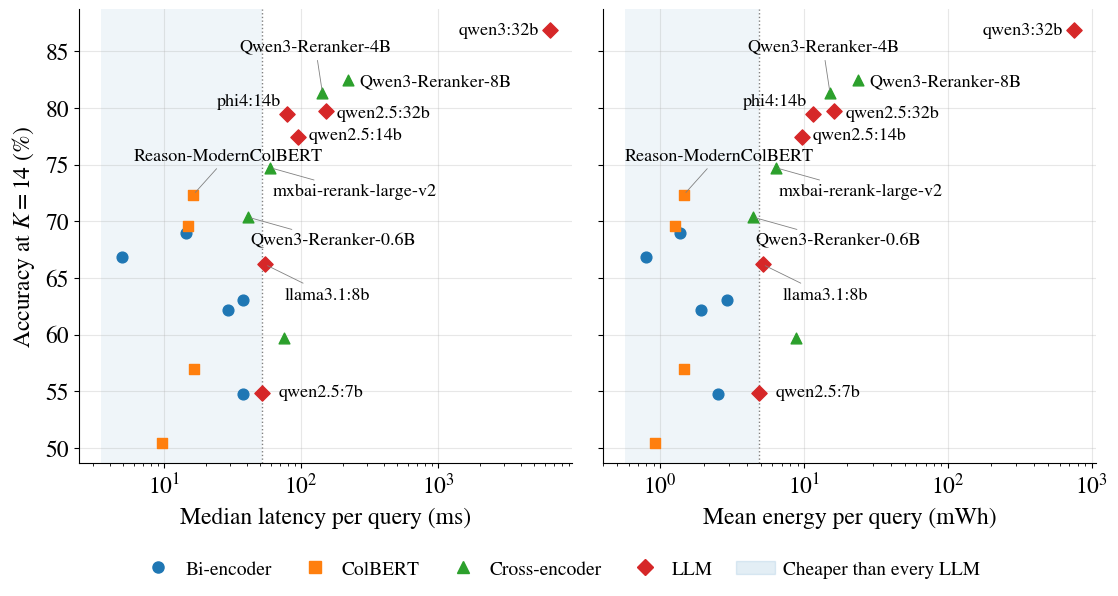

In [313]:
from matplotlib.lines import Line2D

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 17, "axes.titlesize": 17, "axes.labelsize": 17,
                     "xtick.labelsize": 17, "ytick.labelsize": 17, "legend.fontsize": 16})

style = {"bi-encoder":    ("o", "tab:blue",   "Bi-encoder"),
         "colbert":       ("s", "tab:orange", "ColBERT"),
         "cross-encoder": ("^", "tab:green",  "Cross-encoder"),
         "llm":           ("D", "tab:red",    "LLM")}

# offsets (dx, dy in points) for the models named in the text
labels = {"Reason-ModernColBERT": (25, 25),
          "mxbai-rerank-large-v2": (61, -20),
          "qwen3:32b":            (-8, -3),
          "Qwen3-Reranker-8B":    (8, -4),
          "qwen2.5:14b":          (8, -2),
          "Qwen3-Reranker-0.6B":  (61, -20),
          "Qwen3-Reranker-4B":    (-5, 30),
          "phi4:14b":             (-4, 6),
          "qwen2.5:32b":          (8, -5),
          "llama3.1:8b":          (45, -25),
          "qwen2.5:7b":          (12, -3)}
         

acc_col = "Acc. K=14 (%)"
panels = [("Lat. K=14 (ms)",    "Median latency per query (ms)"),
          ("Energy K=14 (mWh)", "Mean energy per query (mWh)")]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.0), sharey=True)
for ax, (col, xlabel) in zip(axes, panels):
    for fam, (marker, color, name) in style.items():
        sub = table_cost.loc[fam]
        ax.scatter(sub[col], sub[acc_col], marker=marker, color=color, s=60, zorder=3)

    for (fam, router), r in table_cost.iterrows():
        short = router.split("/")[-1]
        if short in labels:
            dx, dy = labels[short]
            far = abs(dx) > 20 or abs(dy) > 20
            ha = "center" if far or dx == 0 else "right" if dx < 0 else "left"
            ax.annotate(short, (r[col], r[acc_col]), xytext=(dx, dy), textcoords="offset points",
                        ha=ha, fontsize=13,
                        arrowprops=dict(arrowstyle="-", lw=0.6, color="gray") if far else None)

    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.grid(alpha=0.3)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

    # (1) shaded zone: cheaper than every LLM (left of the cheapest LLM)
    llm_min = table_cost.loc["llm"][col].min()
    ax.axvspan(ax.get_xlim()[0], llm_min, color="tab:blue", alpha=0.07, zorder=0, lw=0)
    ax.axvline(llm_min, color="gray", lw=1.0, ls=":", zorder=1)
    ax.set_xlim(left=ax.get_xlim()[0])     # keep the axis from growing because of the shading

axes[0].set_ylabel("Accuracy at $K=14$ (%)")

# (2) legend entry for the zone, (3) five columns so it fits on one row
handles = [Line2D([], [], marker=m, ls="", color=c, ms=8, label=n) for m, c, n in style.values()]
handles.append(plt.Rectangle((0, 0), 1, 1, color="tab:blue", alpha=0.12, label="Cheaper than every LLM"))
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=14,
           bbox_to_anchor=(0.5, -0.02), columnspacing=1.2, handletextpad=0.4)

plt.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig("cost_scatter.pdf", bbox_inches="tight")
plt.show()

In [306]:
vram = pd.Series({
    "BAAI/bge-large-en-v1.5": 1.83,
    "Qwen/Qwen3-Embedding-0.6B": 1.82,
    "Qwen/Qwen3-Embedding-4B": 8.37,
    "Qwen/Qwen3-Embedding-8B": 14.96,
    "sentence-transformers/all-MiniLM-L6-v2": 0.63,
    "LiquidAI/LFM2-ColBERT-350M": 1.96,
    "colbert-ir/colbertv2.0": 1.01,
    "lightonai/Reason-ModernColBERT": 1.13,
    "mixedbread-ai/mxbai-colbert-large-v1": 1.19,
    "BAAI/bge-reranker-v2-m3": 3.70,
    "Qwen/Qwen3-Reranker-0.6B": 2.86,
    "Qwen/Qwen3-Reranker-4B": 10.94,
    "Qwen/Qwen3-Reranker-8B": 19.51,
    "mixedbread-ai/mxbai-rerank-large-v2": 5.91,
    "llama3.1:8b": 21.72,
    "phi4:14b": 12.05,
    "qwen2.5:14b": 14.73,
    "qwen2.5:32b": 27.02,
    "qwen2.5:7b": 6.64,
    "qwen3:32b": 29.80,
}, name="Peak GPU mem. (GiB)")

table_final_cost = table_cost.reset_index().join(vram, on="model_name")
# table_final_cost.to_latex()
table_final_cost

,routing_method,model_name,Acc. K=14 (%),Lat. K=14 (ms),Energy K=14 (mWh),Peak GPU mem. (GiB)
0,bi-encoder,BAAI/bge-large-en-v1.5,69.00,14.38,1.36,1.83
1,bi-encoder,Qwen/Qwen3-Embedding-0.6B,62.18,29.33,1.91,1.82
2,bi-encoder,Qwen/Qwen3-Embedding-4B,54.76,37.58,2.51,8.37
3,bi-encoder,Qwen/Qwen3-Embedding-8B,63.06,37.43,2.91,14.96
4,bi-encoder,sentence-transformers/all-MiniLM-L6-v2,66.82,4.94,0.80,0.63
5,colbert,LiquidAI/LFM2-ColBERT-350M,69.59,14.77,1.27,1.96
6,colbert,colbert-ir/colbertv2.0,50.47,9.56,0.91,1.01
7,colbert,lightonai/Reason-ModernColBERT,72.35,16.30,1.46,1.13
8,colbert,mixedbread-ai/mxbai-colbert-large-v1,56.94,16.35,1.45,1.19
9,cross-encoder,BAAI/bge-reranker-v2-m3,59.71,75.32,8.77,3.70


In [307]:
energy_check = (k14_cost.groupby(["routing_method", "model_name"])["energy_mwh"]
                .agg(["mean", "median"])
                .round(3))
energy_check

mean   median
routing_method model_name                                              
bi-encoder     BAAI/bge-large-en-v1.5                    1.364    0.060
               Qwen/Qwen3-Embedding-0.6B                 1.905    1.660
               Qwen/Qwen3-Embedding-4B                   2.508    1.694
               Qwen/Qwen3-Embedding-8B                   2.907    1.709
               sentence-transformers/all-MiniLM-L6-v2    0.799    0.032
colbert        LiquidAI/LFM2-ColBERT-350M                1.273    0.062
               colbert-ir/colbertv2.0                    0.909    0.044
               lightonai/Reason-ModernColBERT            1.459    0.066
               mixedbread-ai/mxbai-colbert-large-v1      1.451    0.064
cross-encoder  BAAI/bge-reranker-v2-m3                   8.769    9.021
               Qwen/Qwen3-Reranker-0.6B                  4.427    5.726
               Qwen/Qwen3-Reranker-4B                   15.124   17.390
               Qwen/Qwen3-Reranker-8B                   23.825   21.195
               mixedbread-ai/mxbai-rerank-large-v2       6.372    7.875
llm            llama3.1:8b                               5.150    6.175
               phi4:14b                                 11.438    8.312
               qwen2.5:14b                               9.598    8.103
               qwen2.5:32b                              16.213   17.948
               qwen2.5:7b                                4.855    6.114
               qwen3:32b                               754.640  660.919

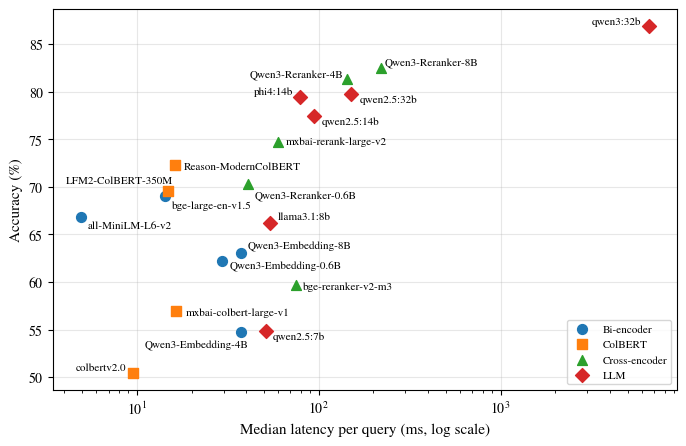

In [36]:
plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

# 1. Prepare the data from table_cost
plot_df = table_cost.reset_index().rename(columns={
    "routing_method": "family",
    "Lat. K=14 (ms)": "latency",
    "Acc. K=14 (%)":  "accuracy",
})
plot_df["label"] = plot_df["model_name"].str.split("/").str[-1]

# 2. Same style as the recall scatter: (marker, colour, legend name)
style = {"bi-encoder": ("o", "tab:blue", "Bi-encoder"),
         "colbert": ("s", "tab:orange", "ColBERT"),
         "cross-encoder": ("^", "tab:green", "Cross-encoder"),
         "llm": ("D", "tab:red", "LLM")}

offsets = {
    # bi-encoders
    "all-MiniLM-L6-v2":              ( 5, -6, "left"),
    "bge-large-en-v1.5":             ( 5, -6, "left"),
    "Qwen3-Embedding-0.6B":          ( 6, -3, "left"), #left/right, up/down
    "Qwen3-Embedding-4B":            (5,  -9, "right"),
    "Qwen3-Embedding-8B":            ( 5,  5, "left"),
    # ColBERT
    "colbertv2.0":                   (-5,  4, "right"),
    "LFM2-ColBERT-350M":             (4,  8, "right"),
    "Reason-ModernColBERT":          ( 6,  -1, "left"),
    "mxbai-colbert-large-v1":        ( 7, -1, "left"),
    # cross-encoders
    "Qwen3-Reranker-0.6B":           ( 5, -9, "left"),
    "mxbai-rerank-large-v2":         ( 6, 1, "left"),
    "bge-reranker-v2-m3":            ( 5,  -1, "left"),
    "Qwen3-Reranker-4B":             (-2,  3, "right"),
    "Qwen3-Reranker-8B":             (3,  4, "left"),
    # LLMs
    "llama3.1:8b":                   ( 5,  5, "left"),
    "qwen2.5:7b":                    ( 5, -4, "left"),
    "phi4:14b":                      (-5,  4, "right"),
    "qwen2.5:14b":                   ( 6, -4, "left"),
    "qwen2.5:32b":                   ( 6, -4, "left"),
    "qwen3:32b":                     (-5,  4, "right"),
}

# 3. Plot
fig, ax = plt.subplots(figsize=(7, 4.6))

for fam, (marker, color, name) in style.items():
    s = plot_df[plot_df["family"] == fam]
    ax.scatter(s["latency"], s["accuracy"], marker=marker, color=color,
               s=50, label=name, zorder=3)

for _, r in plot_df.iterrows():
    if pd.isna(r["latency"]) or pd.isna(r["accuracy"]):    # LLMs: no K=14 data yet
        continue
    dx, dy, align = offsets.get(r["label"], (5, 3, "left"))
    ax.annotate(r["label"], (r["latency"], r["accuracy"]), xytext=(dx, dy),
                textcoords="offset points", ha=align, va="center", fontsize=8)

ax.set_xscale("log")
ax.set_xlabel("Median latency per query (ms, log scale)")
ax.set_ylabel("Accuracy (%)")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
# plt.savefig("cost_scatter.pdf")
plt.show()